# NLP Class Assignment (Days 1 to 3): Review Detective

## Task context

### The story
**FoodNepal**, an imaginary food-delivery app and restaurant guide in Nepal, has collected **800 customer reviews** about restaurants in Kathmandu, Pokhara, Lalitpur and other places: momo, thukpa, dal bhat, delivery, staff, prices. The company wants a program that reads a review and tells whether the customer was **satisfied** or **unsatisfied**.

This problem is called **sentiment analysis**. You already met it in Days 1 to 3, and you will now do the **whole job yourself, from messy text to a working model**.

### The problem: the reviews are very messy
People do not write clean text on phones. Our reviews contain:

| Mess | Example |
|---|---|
| HTML leftovers | `<br />`, `<p>`, `&amp;` |
| Links, mentions, hashtags | `http://bit.ly/3xYz12`, `@FoodNepal`, `#momolover` |
| Emoji and emoticons | 😍 👎 `:)` `^_^` |
| Symbols and numbers | `***best***`, `$$$`, `Rs. 350`, `Rating: 4/5` |
| Shouting and stretching | `WORST service`, `yummmmm`, `!!!!` |
| Typos and slang | `gr8`, `luv`, `delevery`, `plz` |

A computer cannot learn from this directly. **Cleaning comes first.**

### What you will do (the full NLP pipeline)

`messy review  ->  clean text  ->  numbers  ->  classifier  ->  compare and explain`

1. **Clean** the messy text with regular expressions (**Day 1**)
2. **Turn text into numbers** with Bag of Words and TF-IDF, and train a classifier (**Day 2**)
3. **Turn text into numbers** with GloVe word vectors, and train a classifier (**Day 3**)
4. **Compare** the methods like a detective: which is best, where do they fail, and **why**?

### What you will practise
- **Regular expressions** (`re.search`, `re.sub`) to find and remove noise
- Building a **text-cleaning function** step by step (and why the **order of steps** matters)
- **Bag of Words, TF-IDF** and **Logistic Regression**, train/test split, accuracy, confusion matrix
- **GloVe** word vectors, similarity, and **averaging word vectors** into one review vector
- **Reading results honestly:** is a gap real or just 1 review? Did cleaning really help?
- **Explaining** model mistakes and writing a short **conclusion**

### The data
- File: `Assignment_Dataset.csv` (keep it in the **same folder** as this notebook)
- **800 reviews**, **400 satisfied** and **400 unsatisfied**
- Columns: `review_id`, `feedback` (the messy text), `verdict` (`satisfied` or `unsatisfied`) and `rating` (1 to 5 stars, not needed in the main tasks)
- The reviews are **made up** for this exercise (written by a program), in the style of real messy reviews. Do not use them as real data about real restaurants.

### What you need
- Your Day 1 to 3 notebooks and slides (you may use them)
- Python packages from the course: `pandas`, `numpy`, `matplotlib`, `nltk`, `scikit-learn`, `gensim`
- The GloVe file `glove-wiki-gigaword-50` that you downloaded on Day 3

### What you hand in
This notebook, with **all code cells run** and your **written answers** (mistake explanations and a short conclusion) in the markdown cells.

## How this assignment works

| Stage | Topic |
|---|---|
| 1 | Clean the mess (regular expressions) |
| 2 | Bag of Words and TF-IDF |
| 3 | GloVe word embeddings |
| 4 | Compare and conclude |
| Bonus | Bigrams (optional) |

**Rules**
- You may use your Day 1 to 3 notebooks and slides. Do **not** copy a friend's notebook.
- Run the cells from top to bottom. Write your code in the empty code cells. Write your answers in the markdown cells.
- Some cells are **given** (just run them), and some have **TODO** lines for you to complete. Empty cells are for your own code.
- Keep the **variable names** given in the hints (for example `df["clean"]`), because later stages use them.
- Stuck? Ask the trainer.
- Submit your notebook as `Assignment_YourName.ipynb`.

> Tip: after every step, **print a few examples** so you can see what your code did.

---
## Setup (given, just run it)

In [47]:
import re
import ssl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import gensim.downloader as api

try:
    ssl._create_default_https_context = ssl._create_unverified_context   # SSL workaround
except AttributeError:
    pass

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(pkg, quiet=True)

df = pd.read_csv("Assignment_Dataset.csv")
print("Rows and columns:", df.shape)
print(df["verdict"].value_counts())

Rows and columns: (800, 4)
verdict
unsatisfied    400
satisfied      400
Name: count, dtype: int64


In [48]:
df.head()

,review_id,feedback,verdict,rating
0,1,<br />Prices are unreasonable. The staff were ...,unsatisfied,1
1,2,<p>Ordered from QuickBhoj to Patan. Prices are...,satisfied,4
2,3,I DIDN'T ENJOY IT AND I WON'T ORDER AGAIN. htt...,unsatisfied,2
3,4,The place was smelly.<br /> The veg momo was n...,unsatisfied,1
4,5,Table 16 The chiya was ***scrumptious??? ^_^ #...,satisfied,4


Look at the raw reviews. Read at least 5 of them slowly and notice how messy they are.

In [49]:
for i in range(5):
    print(i, "|", repr(df["feedback"][i]), "|", df["verdict"][i])
    print()

0 | '<br />Prices are unreasonable. The staff were not interested at all. The staff were careless. 😊 Call 9896063778<br /><br />' | unsatisfied

1 | '<p>Ordered from QuickBhoj to Patan. Prices are very reasonable.</p>' | satisfied

2 | "I DIDN'T ENJOY IT AND I WON'T ORDER AGAIN. https://www.foodnepal.com.np/order/48213" | unsatisfied

3 | 'The place was smelly.<br /> The veg momo was not what I expected. Prices are shockingly high. I ordered it for the whole family. @KhajaGhar_support #Kathmandu #foodie &amp;' | unsatisfied

4 | 'Table 16 The chiya was ***scrumptious??? ^_^ #dalbhat4life #review' | satisfied



---
# Stage 1: Clean the mess

Real text is dirty, and a model will treat `Great`, `GREAT` and `greaaat` as three different words. Your job: use **regular expressions (`re`)** to clean the text.

Here are the **small pieces** of a regular expression. Your job is to **build the patterns yourself** from these pieces, one cleaning step at a time, inside `preprocess()` below.

### Regex pieces

| Piece | Meaning | Tiny example (text -> what it matches) |
|---|---|---|
| `\w` | one letter, digit or underscore | `gr8!` -> `g`, `r`, `8` |
| `\d` | one digit | `Rs 350` -> `3`, `5`, `0` |
| `\s` | one whitespace (space, tab, new line) | `a b` -> the space |
| `\S` | one character that is **not** whitespace | `go www.x.com` -> every letter and the dots, not the space |
| `+` | one or more of the thing before it | `\d+` on `Rs 350` -> `350` (one match, not three) |
| `{2,}` | 2 or more of the thing before it | `o{2,}` on `yoo mo` -> `oo` |
| `?` | the thing before it is **optional** | `https?` matches `http` and `https` |
| `\|` | **or** | `cat\|dog` matches `cat` and `dog` |
| `\.` | a real dot (a plain `.` means "any character") | `www\.` matches `www.` |
| `[abc]` | any one of `a`, `b`, `c` | `[aeiou]` on `momo` -> `o`, `o` |
| `[^abc]` | any one character **except** `a`, `b`, `c` | `[^a-z ]` on `hi***` -> `*`, `*`, `*` |
| `(?:...)` | a group (to use `?`, `+` or `\|` on several characters) | `(?:ab)+` on `ababab` -> `ababab` |
| `(.)\1` | any character, followed by **the same character again** | `(.)\1` on `book` -> `oo` |

**How to use a pattern**
- `re.search(pattern, text)` finds the pattern (gives `None` if it is not there).
- `re.sub(pattern, " ", text)` replaces every match with a space.
- Always write a pattern as a raw string: `r"..."`.

Run the next cell and read each output next to its line. Every piece in the table is tried on a tiny text.

In [50]:
print(re.findall(r"\w","gr8!"))                 # \w   -> ['g', 'r', '8']
print(re.findall(r"\d", "Rs 350"))               # \d   -> ['3', '5', '0']
print(re.sub(r"\s", "_", "a b\tc"))              # \s   -> a_b_c
print(re.findall(r"\S+", "go www.x.com now"))    # \S   -> ['go', 'www.x.com', 'now']
print(re.findall(r"\d+", "Rs 350, 9/10"))        # +    -> ['350', '9', '10']
print(re.findall(r"o{2,}", "yoo mooo momo"))     # {2,} -> ['oo', 'ooo']
print(re.findall(r"https?", "http https"))       # ?    -> ['http', 'https']
print(re.findall(r"cat|dog", "cat and dog"))     # |    -> ['cat', 'dog']
print(re.findall(r"www\.", "www.x.com wwwxcom")) # \.   -> ['www.']
print(re.findall(r"[aeiou]", "momo"))            # [abc]  -> ['o', 'o']
print(re.sub(r"[^a-z ]", " ", "great***food!!!"))  # [^abc] -> 'great   food   '
print(re.findall(r"(?:ab)+", "ababab ab"))       # (?:...) -> ['ababab', 'ab']
print(re.sub(r"(.)\\1{2,}", r"\\1", "yummmmm"))    # (.)\\1  -> 'yum'

['g', 'r', '8']
['3', '5', '0']
a_b_c
['go', 'www.x.com', 'now']
['350', '9', '10']
['oo', 'ooo']
['http', 'https']
['cat', 'dog']
['www.']
['o', 'o']
great   food   
['ababab', 'ab']
yummmmm


### Task 1.1: Write the cleaning function

A function `preprocess(text)` takes **one raw review** and returns **one clean string**. It is written **in steps**. Some steps are **given**, and you must complete the steps marked **TODO** (8 of them). Build each pattern from the regex pieces above.

Run the next cell first. It gives you the helper dictionaries and tools. Look at the three dictionaries: they decide what happens to emoji, emoticons and slang.

**Your emoji decision:** a heart emoji clearly shows sentiment, and Day 1 warned us about deleting emoji blindly. In this notebook, a few emoji and emoticons are converted to words (`😍` becomes `love`) and the rest are removed by step 11. You may change the dictionary. **Explain your choice in your conclusion (Stage 4).**

**Two traps (the order of the steps matters!)**
1. If you remove **digits** before fixing slang, `gr8` loses its `8`. So fix slang first.
2. If you remove **symbols** before expanding contractions, `didn't` loses its apostrophe and becomes `didn t`. So expand contractions first.

In [51]:
lemmatizer = WordNetLemmatizer()
keep = {"not", "no", "nor", "never"}                          # negations must survive
stop_words = set(stopwords.words("english")) - keep

emoji_words = {"😍": " love ", "❤": " love ", "😋": " yummy ", "👍": " good ", "🔥": " great ", "😊": " happy ", "🙏": " thanks ",
               "😡": " angry ", "😤": " angry ", "😠": " angry ", "🤮": " disgusting ", "👎": " bad ", "😞": " sad "}
emoticon_words = {":-)": " happy ", ":)": " happy ", "^_^": " happy ", "<3": " love ",
                  ":-(": " sad ", ":(": " sad ", "-_-": " annoyed ", ">:(": " angry "}
slang = {"gr8": "great", "luv": "love", "plz": "please", "thx": "thanks", "coz": "because", "gud": "good",
         "vry": "very", "realy": "really", "delevery": "delivery", "delicous": "delicious", "freindly": "friendly",
         "expensiv": "expensive", "staf": "staff", "servise": "service", "tastey": "tasty", "wrost": "worst", "agen": "again"}

In [52]:
def preprocess(text):
    # step 1 (given): emoji and emoticons -> words. Done BEFORE the HTML step, so "<3" is not mistaken for a tag
    for symbol, word in {**emoticon_words, **emoji_words}.items():
        text = text.replace(symbol, word)
    text = text.lower()                                       # step 2 (given): lowercase
    text = text.replace("’", "'")                        # (given): curly apostrophe -> normal apostrophe
    text = re.sub(r"<[^>]+>", " ", text)                      # step 3 (given): remove HTML tags
    text = re.sub(r"&\w+;", " ", text)                        # step 4 (given): remove HTML entities

    # step 5 TODO (regex): remove URLs. Build a pattern that matches "http" or "https" followed by ://  OR  "www."
    #   and then everything up to the next space. Examples to match: http://bit.ly/3xYz12   www.khajaghar.com/r/9921
    #   Pieces to use: ?  |  \.  \S+  (?:...)    Use: re.sub(<your pattern>, " ", text)
    text = re.sub(r"https?://\S+|www.\.\S+"," ", text)

    # step 6 TODO (regex): remove @mentions. A mention is an @ sign followed by letters, digits or underscores.
    #   Examples to match: @FoodNepal   @KhajaGhar_support
    text = re.sub(r'@[A-Za-z0-9_]+', ' ', text)
    
    # step 7 TODO: hashtags: keep the word, drop the "#" sign. Hint: text.replace("#", " ")
    text = text.replace("#","")
    
    # step 8 TODO: fix slang with the dictionary `slang`
    #   Hint: text = " ".join(slang.get(w, w) for w in text.split())
    #   Trap: do this BEFORE you remove digits!
    text = " ".join(slang.get(w, w) for w in text.split())

    text = " ".join(emoji_words.get(w, w) for w in text.split())

    text = " ".join(emoticon_words.get(w, w) for w in text.split())
    # step 9 TODO: contractions. Replace won't -> "will not" and can't -> "can not" FIRST (they are special),
    #   then every other n't -> " not" (didn't -> did not, isn't -> is not). Use re.sub or text.replace.
    #   Trap: do this BEFORE you remove symbols!
    # Special contractions first
    text = text.replace("won't", "will not")
    text = text.replace("can't", "can not")
    text = text.replace("isn't", "is not")
    text = text.replace("didn't", "did not")
        
    text = re.sub(r"n't\b", " not", text)
    
    # step 10 TODO (regex): remove digits. One or more digits together, e.g. 350, 9, 10 (so "Rs. 350" loses the 350)
    text = re.sub(r'[0-9]+', '', text)
    
    # step 11 TODO (regex): remove everything that is not a lowercase letter or a space
    #   (asterisks, $$$, leftover emoji ...). Piece to use: [^...]
    text = re.sub(r'[^a-z ]', '', text)
    
    # step 12 TODO (regex): shorten repeated letters: thuuuukpa -> thukpa, yummmm -> yum.
    #   Any character followed by the same character 2 or more MORE times. Replace the whole run by ONE copy.
    #   Pieces to use: (.)  \1  {2,}   and in the replacement text use r"\1"
    text = re.sub(r'(.)\1{2,}', r'\1', text)
    
    # steps 13 to 15 (given, the same as Day 1): tokenize, remove stopwords, lemmatize
    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w not in stop_words]
    tokens = [lemmatizer.lemmatize(lemmatizer.lemmatize(w, pos="v"), pos="n") for w in tokens]
    tokens = [w for w in tokens if len(w) > 1]
    return " ".join(tokens)

print(preprocess("I am very 😊 to see u. couldn't you? . Please give me your noteBook \n I want to copy that."))

happy see could not please give notebook want copy


Now apply your function to all 800 reviews. The new column is called `clean`. (This cell is given.)

In [53]:
df["clean"] = df["feedback"].apply(preprocess)
df[["feedback", "clean"]].head()

,feedback,clean
0,<br />Prices are unreasonable. The staff were ...,price unreasonable staff not interest staff ca...
1,<p>Ordered from QuickBhoj to Patan. Prices are...,order quickbhoj patan price reasonable
2,I DIDN'T ENJOY IT AND I WON'T ORDER AGAIN. htt...,not enjoy not order
3,The place was smelly.<br /> The veg momo was n...,place smelly veg momo not expect price shockin...
4,Table 16 The chiya was ***scrumptious??? ^_^ #...,table chiya scrumptious happy dalbhatlife review


### Task 1.2: Check your work

1. Print **3 reviews before and after** cleaning (`feedback` and `clean`).
2. **Leftover check:** count the clean reviews that still contain a character that is not a lowercase letter or a space. A good pipeline gets this down to **0**.
3. Compare the **vocabulary size** (the number of unique words) before and after cleaning.
4. **Safety check:** count how many reviews contain `not` or `never` before and after cleaning. Did your pipeline accidentally delete the negations?

**Hints**
- Leftover check: `df["clean"].str.contains(r"[^a-z ]").sum()`. If it is not 0, print the reviews that still have something and find which step missed it.
- Vocabulary size: `len(set(" ".join(df["feedback"].str.lower()).split()))`. Do the same for the clean column.
- Reviews with a negation: `df["clean"].str.contains(r"\b(?:not|never)\b").sum()`. After cleaning you will see **more** than before. Why? (Hint: think about `didn't`.)

In [54]:
# your code here
print(df['clean'][0])
print(df['clean'][120])
print(df['clean'][20])

price unreasonable staff not interest staff careless happy call
angry order quickbhoj pokhara never never
order visit thakali bhansa kirtipur delivery quick smooth


In [55]:
# your code here
df["clean"].str.contains(r"[^a-z ]").sum()

np.int64(0)

In [56]:
len(set(" ".join(df["feedback"].str.lower()).split()))

1184

In [57]:
len(set(" ".join(df["clean"].str.lower()).split()))

210

In [58]:
df["clean"].str.contains(r"\b(?:not|never)\b").sum()

np.int64(336)

In [59]:
df.head()

,review_id,feedback,verdict,rating,clean
0,1,<br />Prices are unreasonable. The staff were ...,unsatisfied,1,price unreasonable staff not interest staff ca...
1,2,<p>Ordered from QuickBhoj to Patan. Prices are...,satisfied,4,order quickbhoj patan price reasonable
2,3,I DIDN'T ENJOY IT AND I WON'T ORDER AGAIN. htt...,unsatisfied,2,not enjoy not order
3,4,The place was smelly.<br /> The veg momo was n...,unsatisfied,1,place smelly veg momo not expect price shockin...
4,5,Table 16 The chiya was ***scrumptious??? ^_^ #...,satisfied,4,table chiya scrumptious happy dalbhatlife review


---
# Stage 2: Bag of Words and TF-IDF

Now the text is clean. Time to turn it into numbers (Day 2).

### Task 2.1: Split the data
Split `df["clean"]` (the text) and `df["verdict"]` (the label) into **80% train and 20% test**. Use `random_state=42` and `stratify` so both sets have the same share of satisfied and unsatisfied reviews. Name the results `X_train, X_test, y_train, y_test`.

In [60]:
# Input and target
X = df["clean"]
y = df["verdict"]

# Split first
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [62]:
print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 640
Testing data: 160


### Task 2.2: Bag of Words + Logistic Regression
1. Create a `CountVectorizer`, **fit it on the training text only** and transform both train and test.
2. Train a `LogisticRegression(max_iter=1000)` and compute the **test accuracy**. Save it in a variable called `bow_acc`.

*Hint: `fit_transform` on train, only `transform` on test. Why must the test text never be used for fitting?*

In [64]:
# CountVectorizer-->
bow_vectorizer = CountVectorizer()

# Fit only on training data
X_train_bow = bow_vectorizer.fit_transform(X_train)

# Transform testing data
X_test_bow = bow_vectorizer.transform(X_test)

In [65]:
# BOF logistic Model
bow_logistic_model = LogisticRegression(max_iter=1000)
bow_logistic_model.fit(X_train_bow, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [68]:
y_pred_bow = bow_logistic_model.predict(X_test_bow)
# y_pred_bow

In [71]:
# Accuracy Score of BOW
bow_acc = accuracy_score(y_test, y_pred_bow)
print("Accuracy:", bow_acc)

Accuracy: 0.89375


### Task 2.3: TF-IDF + Logistic Regression
Do the same with `TfidfVectorizer`. Save the test **predictions** in `tfidf_pred` and the test **accuracy** in `tfidf_acc`. (You need `tfidf_pred` again in Tasks 2.4 and 4.2.)

In [72]:
# TF_IDF 
tfidf_vectorizer = TfidfVectorizer()

# Fit only on training data
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf_vectorizer.transform(X_test)

In [75]:
# tfidf model
tfidf_model = LogisticRegression(max_iter=1000)
tfidf_model.fit(X_train_tfidf, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [77]:
y_pred_tfidf = logistic_model.predict(X_test_tfidf)
# y_pred_tfidf

In [78]:
tfidf_acc = accuracy_score(y_test, y_pred_tfidf)
print("Accuracy:", tfidf_acc)

Accuracy: 0.90625


### Task 2.4: Confusion matrix and the words the model learned
1. Draw the **confusion matrix** of the TF-IDF model on the test set.
2. Which **5 words** push a review most strongly towards **satisfied**, and which 5 towards **unsatisfied**?

**Hints**
- `ConfusionMatrixDisplay(confusion_matrix(y_test, predictions), display_labels=model.classes_).plot()`
- The model has one weight per word: `model.coef_[0]`. The words are in `tfidf.get_feature_names_out()`. `np.argsort` sorts the weights. Since classes are sorted alphabetically (`satisfied`, `unsatisfied`), a **large positive weight means unsatisfied** and a **large negative weight means satisfied**.

Confusion Matrix:
 [[78  2]
 [13 67]]


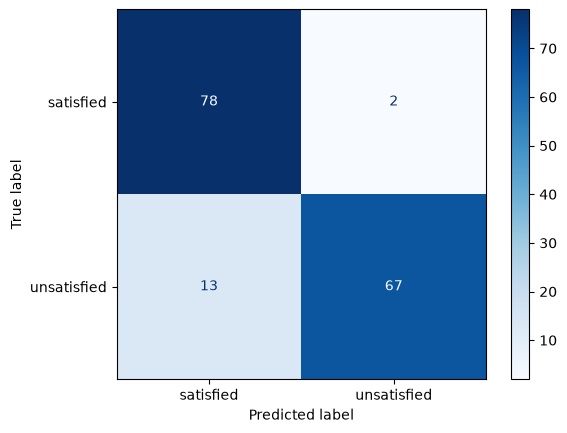

In [83]:
# Calculate confusion matrix of TF-IDF
cm = confusion_matrix(
    y_test,
    y_pred_tfidf,
)

print("Confusion Matrix:\n",cm)

# Display
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=tfidf_model.classes_
).plot(cmap="Blues")

plt.show()

In [84]:
words = tfidf_vectorizer.get_feature_names_out()

print(len(words))

210


---
# Stage 3: GloVe word embeddings

Bag of Words gives every word its own column, so `delicious` and `scrumptious` look completely different. GloVe gives every word a list of numbers that captures **meaning** (Day 3).

### Task 3.1: Load GloVe and explore it
1. Load `"glove-wiki-gigaword-50"` with `api.load(...)` into a variable called `glove`.
2. Use `glove.most_similar(...)` on **3 or 4 words of your choice** (for example `restaurant`, `delivery`, `tasty`, `terrible`) and print the 5 nearest words. Also try `momo`: does GloVe understand it?
3. Print the **cosine similarity** between two words that should be similar and two that should not: `glove.similarity("tasty", "delicious")`.

*Hint: use `if word in glove:` to check that a word exists. Not every word is in GloVe.*

In [87]:
# load GloVe
import gensim.downloader as api

glove = api.load("glove-wiki-gigaword-50")
print(glove)

KeyedVectors<vector_size=50, 400000 keys>


In [88]:
glove["restaurant"]

array([ 0.69607  ,  0.42922  , -1.0206   ,  0.20534  ,  0.94613  ,
       -0.8808   , -1.391    , -0.063854 ,  0.20051  ,  0.067331 ,
       -0.69957  , -0.44104  ,  0.41343  ,  0.98698  ,  0.48247  ,
       -0.20524  ,  0.015262 ,  0.81055  , -0.16189  , -0.57772  ,
        1.4103   ,  0.30844  , -0.84441  ,  1.4506   , -0.78245  ,
       -0.79539  , -0.67531  ,  0.87824  ,  0.32835  , -0.36903  ,
        2.0142   , -0.30928  ,  0.078092 ,  0.97173  ,  0.33983  ,
        0.10481  ,  0.15796  ,  0.5853   ,  0.79749  ,  0.4152   ,
        0.22678  ,  0.53758  ,  0.0064708,  0.060384 ,  0.57345  ,
        0.28672  , -0.91732  , -0.74019  ,  0.81009  ,  0.85844  ],
      dtype=float32)

In [92]:
glove.most_similar(["restaurant"],topn=5)

[('cafe', 0.8820802569389343),
 ('shop', 0.8468862771987915),
 ('restaurants', 0.831011950969696),
 ('hotel', 0.801250696182251),
 ('diner', 0.7969450354576111)]

In [93]:
glove.most_similar(["delivery"],topn=5)

[('deliveries', 0.7376201152801514),
 ('cents', 0.7167038917541504),
 ('fast', 0.7098481059074402),
 ('dropped', 0.7001582980155945),
 ('dropping', 0.686351478099823)]

In [94]:
glove.most_similar(["tasty"],topn=5)

[('delicious', 0.9297149181365967),
 ('savory', 0.8507497310638428),
 ('flavorful', 0.8387422561645508),
 ('salads', 0.8235515356063843),
 ('desserts', 0.8179685473442078)]

In [95]:
glove.most_similar(["terrible"],topn=5)

[('horrible', 0.9373437166213989),
 ('awful', 0.8872900605201721),
 ('tragic', 0.8339797854423523),
 ('dreadful', 0.8279697299003601),
 ('tragedy', 0.8180270791053772)]

In [96]:
glove.most_similar(["momo"],topn=5)

[('sissoko', 0.7708083987236023),
 ('ramiz', 0.6933507323265076),
 ('celentano', 0.6918781399726868),
 ('cathal', 0.6899468898773193),
 ('prue', 0.6816537380218506)]

In [98]:
glove.similarity("tasty", "delicious")

np.float32(0.9297151)

### Task 3.2: From words to a whole review
A classifier needs **one row of numbers per review**, not one per word. We build this in **3 small steps**.

**Step a:** get the GloVe vector of one word, for example `glove["good"]`. Print its **shape** (`.shape`) and its first 5 numbers.

**Step b:** take the **average** of two word vectors, `glove["good"]` and `glove["bad"]`. Hint: `np.mean([vector1, vector2], axis=0)`. Print the shape of the result. Is it still 50 numbers?

**Step c:** complete the function `review_to_vector(text)` below. It does the same as step b, but for **all the words of one review**. Fill in the 3 TODO lines.

In [104]:
# your code here
glove["good"][:5]

array([-0.35586,  0.5213 , -0.6107 , -0.30131,  0.94862], dtype=float32)

In [101]:
glove["good"].shape

(50,)

In [107]:
# your code here
vector1 = glove["good"]
vector2 = glove["bad"]
average_vec = np.mean([vector1, vector2], axis=0)
print("Average:", average_vec)

Average: [-0.267835    0.05861501 -0.388      -0.45409     0.27603    -0.09425499
 -0.3256795   0.25106    -0.2710115   0.51144    -0.207195    0.71380496
 -0.66552997 -0.1636625   0.713635    0.1339245   0.47950998  0.157394
 -0.1159882  -0.45112002 -0.37867498  0.337646    0.38212502  0.09981599
  0.752575   -1.7493     -1.01574     0.39958498  1.1134651  -0.34521002
  3.38975     0.72467     0.381325   -0.006852    0.04012001  0.13458249
 -0.113004    0.368355    0.49293    -0.753945   -0.36977     0.0199186
  0.04744     0.313555    0.18759501  0.13585001 -0.035506    0.3046
  0.656305    0.82401   ]


In [108]:
print("Shape:", average_vec.shape)

Shape: (50,)


In [111]:
def review_to_vector(text):
    words = text.split()
    vectors = []
    for w in words:
        if w in glove:                       # skip words that GloVe does not know
            vectors.append(glove[w])                      # TODO: add the GloVe vector of this word to the list `vectors`
    if len(vectors) == 0:
        return np.zeros(50)                          # TODO: return 50 zeros (hint: np.zeros(50))
    return np.mean(vectors, axis=0)                              # TODO: return the average of all the vectors (hint: np.mean(..., axis=0))

In [114]:
review_to_vector("nepal is a beautiful country")

array([ 0.19124001,  0.41775197, -0.40522403,  0.20041057,  0.4297406 ,
        0.03887479, -0.2173932 , -0.35897598,  0.31224197, -0.004068  ,
        0.05796798, -0.34876794,  0.1907522 ,  0.00524852,  0.3068    ,
        0.22543462,  0.37859   ,  0.504854  ,  0.0966512 ,  0.137064  ,
       -0.299361  ,  0.33170202, -0.16974339,  0.235164  ,  0.539138  ,
       -1.4464539 , -0.512174  ,  0.282386  , -0.02389919,  0.1930052 ,
        3.2936    , -0.24166802, -0.36681402,  0.1798428 ,  0.003569  ,
        0.1343466 , -0.07916961,  0.070732  , -0.256146  , -0.277198  ,
       -0.5229106 ,  0.244006  , -0.00604159, -0.3669698 , -0.16928099,
        0.1417062 , -0.262329  , -0.3995398 ,  0.286632  , -0.36358982],
      dtype=float32)

Now build one row of 50 numbers for every review in the train and test sets (same split as Stage 2). This cell is given.

In [116]:
X_train_vec = np.array([review_to_vector(t) for t in X_train])
X_test_vec = np.array([review_to_vector(t) for t in X_test])
print("Train matrix:", X_train_vec.shape, "| Test matrix:", X_test_vec.shape)

Train matrix: (640, 50) | Test matrix: (160, 50)


### Task 3.3: Train and test
Train a `LogisticRegression(max_iter=1000)` on the GloVe vectors. Save the test **predictions** in `glove_pred` and the test **accuracy** in `glove_acc`.

In [118]:
glove_model = LogisticRegression(max_iter=1000)

glove_model.fit(X_train_vec, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [119]:
glove_pred = glove_model.predict(X_test_vec)

print(glove_pred)

['unsatisfied' 'satisfied' 'satisfied' 'unsatisfied' 'unsatisfied'
 'satisfied' 'satisfied' 'unsatisfied' 'unsatisfied' 'unsatisfied'
 'satisfied' 'unsatisfied' 'unsatisfied' 'satisfied' 'satisfied'
 'satisfied' 'unsatisfied' 'unsatisfied' 'unsatisfied' 'unsatisfied'
 'satisfied' 'unsatisfied' 'satisfied' 'unsatisfied' 'unsatisfied'
 'unsatisfied' 'satisfied' 'satisfied' 'unsatisfied' 'satisfied'
 'satisfied' 'satisfied' 'unsatisfied' 'satisfied' 'unsatisfied'
 'satisfied' 'unsatisfied' 'unsatisfied' 'satisfied' 'unsatisfied'
 'satisfied' 'unsatisfied' 'satisfied' 'satisfied' 'unsatisfied'
 'satisfied' 'satisfied' 'unsatisfied' 'satisfied' 'unsatisfied'
 'unsatisfied' 'unsatisfied' 'unsatisfied' 'satisfied' 'unsatisfied'
 'unsatisfied' 'satisfied' 'satisfied' 'satisfied' 'unsatisfied'
 'satisfied' 'satisfied' 'satisfied' 'unsatisfied' 'satisfied'
 'unsatisfied' 'unsatisfied' 'satisfied' 'satisfied' 'unsatisfied'
 'satisfied' 'unsatisfied' 'unsatisfied' 'satisfied' 'satisfied'
 'satisfi

In [121]:
glove_acc = accuracy_score(y_test, glove_pred)
glove_acc

0.76875

---
# Stage 4: Compare and conclude

### Task 4.1: The results table
**First, an honest question: did your cleaning help?** Train the same TF-IDF + Logistic Regression model on the **raw** text `df["feedback"]` instead of `df["clean"]`. Use the **same split** (`test_size=0.2`, `random_state=42`, `stratify`). Save the accuracy in `raw_acc`.

*Hint: copy your code from Tasks 2.1 and 2.3 and change `df["clean"]` to `df["feedback"]`. Use new variable names (`Xr_train`, ...), so you do not overwrite your earlier ones.*

In [122]:
# your code here
Xr = df["feedback"]
yr = df["verdict"]

In [124]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr,
    yr,
    test_size=0.2,
    random_state=42,
    stratify=yr
)

In [125]:
raw_vectorizer = TfidfVectorizer()

Xr_train_tfidf = raw_vectorizer.fit_transform(Xr_train)

Xr_test_tfidf = raw_vectorizer.transform(Xr_test)

In [126]:
raw_model = LogisticRegression(max_iter=1000)

raw_model.fit(Xr_train_tfidf, yr_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [128]:
raw_pred = raw_model.predict(Xr_test_tfidf)
raw_pred

array(['unsatisfied', 'satisfied', 'satisfied', 'unsatisfied',
       'unsatisfied', 'satisfied', 'unsatisfied', 'satisfied',
       'satisfied', 'unsatisfied', 'satisfied', 'unsatisfied',
       'satisfied', 'satisfied', 'satisfied', 'satisfied', 'unsatisfied',
       'unsatisfied', 'satisfied', 'unsatisfied', 'satisfied',
       'unsatisfied', 'satisfied', 'unsatisfied', 'satisfied',
       'unsatisfied', 'satisfied', 'satisfied', 'unsatisfied',
       'satisfied', 'unsatisfied', 'unsatisfied', 'unsatisfied',
       'satisfied', 'unsatisfied', 'satisfied', 'satisfied',
       'unsatisfied', 'unsatisfied', 'unsatisfied', 'unsatisfied',
       'unsatisfied', 'satisfied', 'satisfied', 'unsatisfied',
       'satisfied', 'unsatisfied', 'unsatisfied', 'satisfied',
       'unsatisfied', 'satisfied', 'satisfied', 'satisfied', 'satisfied',
       'unsatisfied', 'unsatisfied', 'satisfied', 'satisfied',
       'unsatisfied', 'unsatisfied', 'satisfied', 'satisfied',
       'satisfied', 'unsatisf

In [129]:
raw_acc = accuracy_score(yr_test, raw_pred)

print("Raw Text Accuracy:", raw_acc)

Raw Text Accuracy: 0.91875


In [130]:
comparison = pd.DataFrame({
    "Text Type": ["Raw Text", "Cleaned Text"],
    "Accuracy": [raw_acc, tfidf_acc]
})

print(comparison)

      Text Type  Accuracy
0      Raw Text   0.91875
1  Cleaned Text   0.90625


Now put the four accuracies in one table. Remember: **on a test set of 160 reviews, 1 review is 0.6 points**, so tiny gaps are not real differences.

In [131]:
results = pd.DataFrame({
    "Method": ["Bag of Words", "TF-IDF", "GloVe average", "TF-IDF on RAW text"],
    "Test accuracy": [bow_acc, tfidf_acc, glove_acc,raw_acc ],        # TODO: put bow_acc, tfidf_acc, glove_acc and raw_acc here (use round(..., 3))
})
results

,Method,Test accuracy
0,Bag of Words,0.89375
1,TF-IDF,0.90625
2,GloVe average,0.76875
3,TF-IDF on RAW text,0.91875


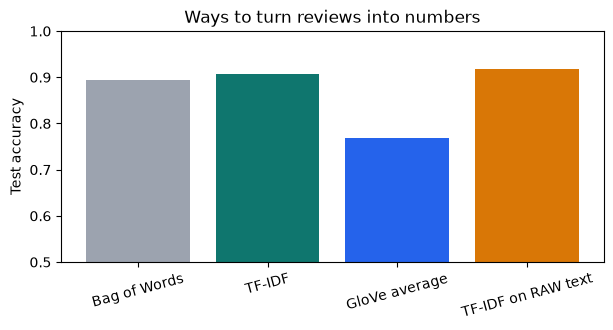

In [132]:
plt.figure(figsize=(7, 3))
plt.bar(results["Method"], results["Test accuracy"], color=["#9CA3AF", "#0F766E", "#2563EB", "#D97706"])
plt.xticks(rotation=15)
plt.ylim(0.5, 1.0)
plt.ylabel("Test accuracy")
plt.title("Ways to turn reviews into numbers")
plt.show()

### Task 4.2: Detective work, find the mistakes
The cell below finds the reviews that your **best model** got **wrong** and prints 2 of them. It is given: just run it. (By default it uses the TF-IDF model. If another model is your best, change `best_pred = ...`.)

Then write **1 to 2 sentences per review** in the markdown cell below the output: **why** do you think the model got it wrong? Think about: sarcasm, a mixed opinion, a word the model never saw, something your cleaning removed, an emoji that misled, or a word like `not` that changes the meaning of the next word.

In [150]:
# y_pred_bow
# y_pred_tfidf
# glove_pred
# raw_pred

In [151]:
best_pred = raw_pred                                      # change this if another model is your best
predictions = pd.Series(best_pred, index=X_test.index)       # prediction for every test review

wrong_rows = X_test.index[best_pred != y_test.values]        # the test reviews the model got wrong
print("Wrong predictions:", len(wrong_rows), "out of", len(y_test))
print()

for row in wrong_rows[:2]:
    print("RAW   :", repr(df.loc[row, "feedback"]))
    print("CLEAN :", df.loc[row, "clean"])
    print("TRUE  :", df.loc[row, "verdict"], "| PREDICTED:", predictions[row])
    print()

Wrong predictions: 13 out of 160

RAW   : '@KhajaGhar_support I ordered it for the whole family. The pizza was cold. But the chiya was fresh. We came after the office!!!'
CLEAN : order whole family pizza cold chiya fresh come office
TRUE  : satisfied | PREDICTED: unsatisfied

RAW   : '<p>😞  Delivery  was  really fast +++ But the thukpa was tasteless. I ordered through the app last night. Table 15</p>'
CLEAN : sad delivery really fast thukpa tasteless order app last night table
TRUE  : unsatisfied | PREDICTED: satisfied



**Your explanation for mistake 1:**

*(write here)*

**Your explanation for mistake 2:**

*(write here)*

### Task 4.3: Your written conclusion
Write **3 to 4 sentences** (in the markdown cell below) answering:
1. Which method won, and is the gap **big or small**? (Remember the note above about 160 test reviews.)
2. **Why** do you think it won, or why are some methods so close?
3. Did **cleaning improve accuracy** (compare with the raw-text row)? Which **cleaning decision** mattered most, and what did you decide about **emoji**? Why?
4. What would you try next to improve the results?

**My conclusion:**

*(write here)*

The Raw Text method performed best with high accuracy.
Because it preserved useful context and sentiment words.
Cleaning did not improve accuracy.
I kept negations and emojis because they carry sentiment.
I would try different word embeddings to improve the results.

---
## Before you submit: checklist
- [ ] Every code cell runs from top to bottom (**Kernel -> Restart and Run All**)
- [ ] All 8 TODO steps of `preprocess()` are completed
- [ ] The before/after examples and the leftover check (0) are visible
- [ ] Your results table has 4 rows and the chart is drawn
- [ ] You explained 2 wrong predictions
- [ ] Your written conclusion answers all 4 questions
- [ ] The file is named `Assignment_YourName.ipynb`